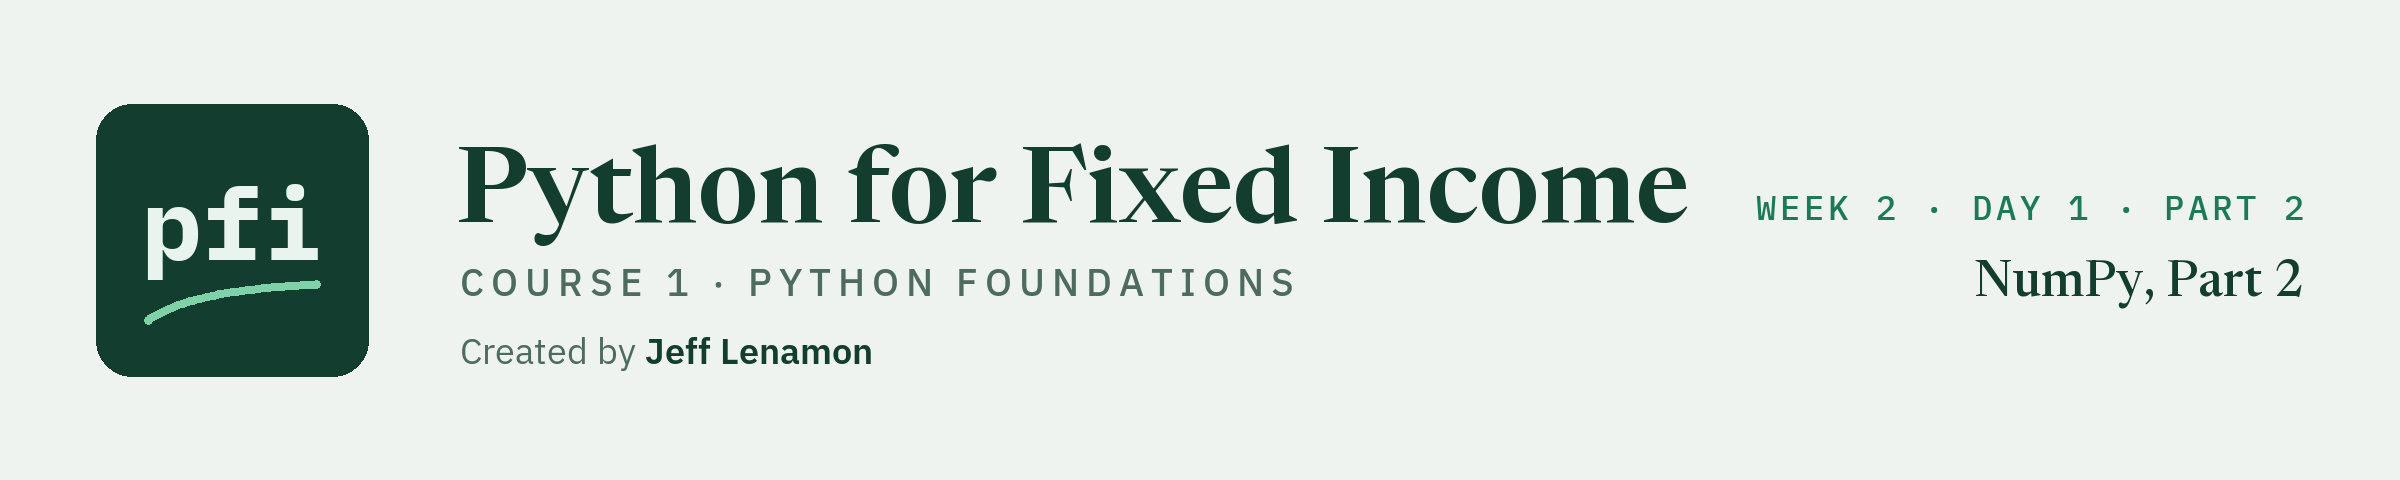

# NumPy, Part 2

Week 2, Day 1, Part 2. Picking out bonds by position and by condition, holding a table in one array, and pricing a bond from its cash flows.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day1_part2/06_part2_numpy.ipynb)

## The Desk Lead's Ninth Note

> This morning's answers covered whole columns. These are about part of one: which bonds are below par, which are high yield, and what if the cheap ones rally a point. Then check our 98.50 on QVNE against its cash flows, value the book for Monday to Thursday, and save it all for tomorrow.

### Part 1's Arrays in One Cell

A new notebook starts empty: this cell rebuilds Part 1's arrays, so every answer checks against Part 1.
`scores` is week 1's rating score: AAA is 1, one more per notch lower; 11 or higher is high yield.

In [1]:
import numpy as np

# Part 1's four bonds, one array per column, in the same order
tickers = np.array(['QVNE', 'DNMR', 'PLWK', 'HLVF'])
coupons = np.array([5.25, 6.125, 4.75, 7.5])
prices = np.array([98.5, 103.25, 95.0, 101.0])
faces = np.array([1500000, 500000, 750000, 250000])
# week 1's rating scores: BBB, BB+, A-, B+
scores = np.array([9, 11, 7, 14])
# 6.3's income and current yield of each bond
incomes = faces * coupons / 100
current_yields = coupons / prices * 100
# 6.3's yields with DNMR's price typed in as 0; np.inf is the inf that division gave
yields_with_zero = np.array([current_yields[0], np.inf, current_yields[2], current_yields[3]])
print(yields_with_zero)

[5.32994924        inf 5.         7.42574257]


## 6.5 Picking Out Bonds

### By Position, as on a List

Q. Print the first price, the third ticker, the first two coupons, and the last face; then show the first price without `print()`.

In [2]:
# an index, a slice, and a negative index, as on a list (week 1's Part 1)
print(prices[0])
print(tickers[2])
print(coupons[0:2])
print(faces[-1])
# the cell's last line, shown without print()
prices[0]

98.5
PLWK
[5.25  6.125]
250000


np.float64(98.5)

Shown bare, 98.5 carries its type, `np.float64`; `print()` shows the value alone.

### Change a Slice

**Predict 1**

Q. A slice of an array is an array. The next cell sets the first value of the slice `prices[0:2]` to 0. What does `prices` print?

A) 98.5 first.
B) 0 first.
C) An error.

In [3]:
# the first two prices, as a slice
first_two = prices[0:2]
# change the slice's first value
first_two[0] = 0
print(prices)

[  0.   103.25  95.   101.  ]


B: a slice is a **view**, a window onto the same numbers, and nothing warned.

### Change a Copy Instead

Q. Put QVNE's 98.5 back, then make the same change on a copy.

In [4]:
# put the real price back
prices[0] = 98.5
# .copy() makes a separate array, as it made a separate list on Day 3
first_two_copy = prices[0:2].copy()
first_two_copy[0] = 0
print(prices)

[ 98.5  103.25  95.   101.  ]


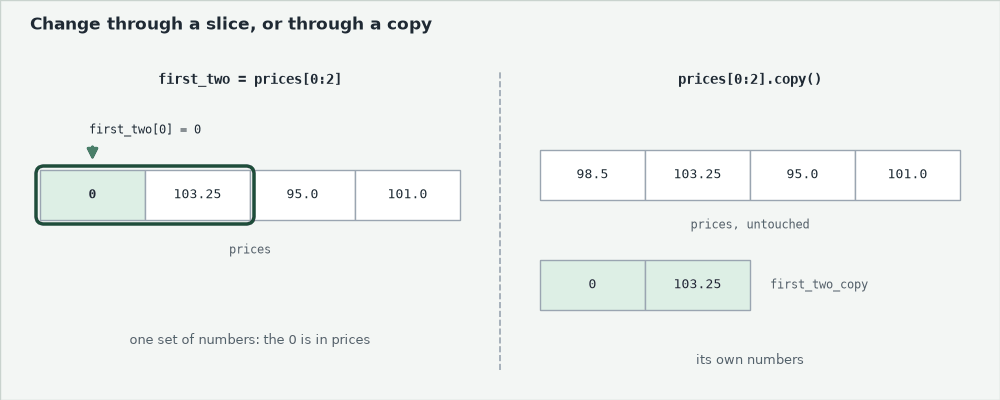

**To change part and keep the original, slice, then `.copy()`.**

### One Past the End

Q. The array holds four values. Ask for position 4.

In [5]:
# positions run from 0: this cell is meant to fail
print(prices[4])

IndexError: index 4 is out of bounds for axis 0 with size 4

Size 4: positions 0 to 3, the last always the size minus 1.

### Several Positions at Once

Q. Print the first and third tickers, then every other price.

In [6]:
# a list of positions in the brackets, as tickers[order] in 6.4
print(tickers[[0, 2]])
# np.arange(0, 4, 2) makes the positions 0 and 2
print(prices[np.arange(0, 4, 2)])

['QVNE' 'PLWK']
[98.5 95. ]


### Below Par: A Mask Picks the Bonds

By position needs to know where; a condition does not.
A comparison on an array gives one True or False per bond: a **boolean mask**.

Q. Which bonds are priced below par?

Q. Which bonds are below par, at what prices, how many, and with how much face?

In [7]:
# a comparison tests every value, as == did in 6.3
below_par = prices < 100
print(below_par)

[ True False  True False]


In [8]:
# a mask in the brackets keeps the values where it is True
print(tickers[below_par])
print(prices[below_par])
# True counts as 1 (week 1's Part 1), so a mask's sum is a count
print('Bonds below par:', below_par.sum())
print('Face below par:', faces[below_par].sum())

['QVNE' 'PLWK']
[98.5 95. ]
Bonds below par: 2
Face below par: 2250000


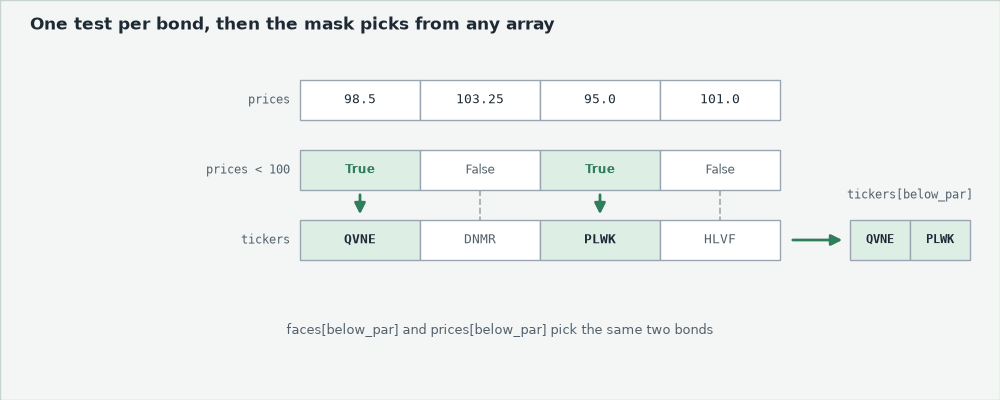

**One comparison, four answers, one bond order.**

### High Yield, Both Tests, or Either

Q. Which bonds are high yield, and what do they pay a year?

Q. Which are high yield and above 102? Which are high yield or below 96?

In [9]:
# the mask written straight into the brackets; incomes is 6.3's
print(tickers[scores >= 11], incomes[scores >= 11].sum())
# & means and, | means or, for masks
# Python does & and | before >= and <: the brackets make each test run first
print(tickers[(scores >= 11) & (prices > 102)])
print(tickers[(scores >= 11) | (prices < 96)])

['DNMR' 'HLVF'] 49375.0
['DNMR']
['DNMR' 'PLWK' 'HLVF']


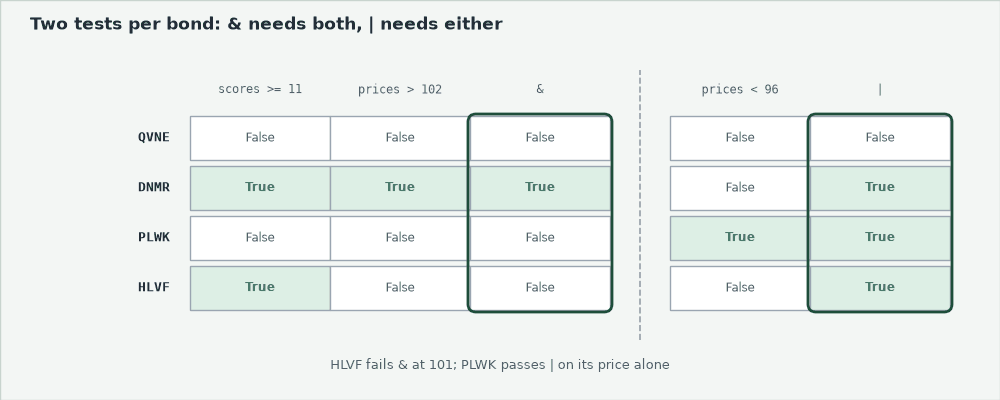

**Week 1 wrote `and` and `or` as words. Try one.**

### And Between Two Masks

**Predict 2**

Q. `and` joined one True or False to another. The next cell puts it between two masks. What happens?

A) DNMR, as with `&`.
B) An error.
C) An empty array.

In [10]:
# the word and between two masks
print(tickers[(scores >= 11) and (prices > 102)])

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

B: `and` needs one True or False and was handed four.

**For masks, the symbols `&` and `|`, never the words.**

### Real Yields Only, Then a Label for Each Bond

Q. Which of 6.3's four yields are real numbers?

Q. Label each bond Premium or Discount; none sits at exactly 100.

In [11]:
# np.isfinite(): True for an ordinary number, False for inf and for nan, 'not a number'
real = np.isfinite(yields_with_zero)
print(real)
print(yields_with_zero[real])

[ True False  True  True]
[5.32994924 5.         7.42574257]


In [12]:
# np.where(test, value where True, value where False), for every bond at once
labels = np.where(prices > 100, 'Premium', 'Discount')
print(labels)

['Discount' 'Premium' 'Discount' 'Premium']


**Excel side by side.** Ticker in A, face in B, price in C, yield in F:

<table align="left">
<tr><th align="left">Question</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Keep the real yields</td><td align="left"><code>np.isfinite(yields_with_zero)</code></td><td align="left"><code>=ISNUMBER(F2)</code> filled down: FALSE for <code>#DIV/0!</code></td></tr>
<tr><td align="left">Label each bond</td><td align="left"><code>np.where(prices &gt; 100, 'Premium', 'Discount')</code></td><td align="left"><code>=IF(C2&gt;100, "Premium", "Discount")</code> filled down</td></tr>
<tr><td align="left">Count the bonds below par</td><td align="left"><code>(prices &lt; 100).sum()</code></td><td align="left"><code>=COUNTIF(C2:C5, "&lt;100")</code></td></tr>
<tr><td align="left">Face below par</td><td align="left"><code>faces[prices &lt; 100].sum()</code></td><td align="left"><code>=SUMIF(C2:C5, "&lt;100", B2:B5)</code></td></tr>
<tr><td align="left">Tickers below par</td><td align="left"><code>tickers[prices &lt; 100]</code></td><td align="left"><code>=FILTER(A2:A5, C2:C5&lt;100)</code> (Excel 2021, Microsoft 365)</td></tr>
</table>
<br clear="left">

**No loop and no `if`: one line labels the book.**

### A What-If on a Copy

Q. What if every bond below par rallies a point? The real prices must not move.

Q. In another copy, set the first two prices to 99 and 104, and the rest to 100.

In [13]:
# a separate array for the what-if
what_if = prices.copy()
# a mask on the left of = changes only the bonds where it is True
what_if[below_par] = what_if[below_par] + 1
print('What-if: ', what_if)
print('Original:', prices)

What-if:  [ 99.5  103.25  96.   101.  ]
Original: [ 98.5  103.25  95.   101.  ]


In [14]:
# another copy; a list on the right gives each position its own value
edited = prices.copy()
edited[0:2] = [99.0, 104.0]
# a single number on the right fills every position
edited[2:] = 100
print(edited)

[ 99. 104. 100. 100.]


Without `.copy()`, `what_if = prices` gives one array two names, as on Day 3, and the rally lands on the real prices.
On the right of `=`, a mask picks a copy, not a window.

**A mask or a slice on the left of `=` changes just those bonds. Now the note's bond.**

## 6.6 Pricing a Bond From Its Cash Flows

A bond's price is the **present value** of its cash flows: each payment times its discount factor (week 1's Part 1), added up.
We price QVNE, the 5.25 percent bond, per 100 face, on three assumptions:

<table align="left">
<tr><th align="left">Assumption</th><th align="left">Meaning</th></tr>
<tr><td align="left">Whole periods</td><td align="left">7 years exactly: 14 semiannual coupons</td></tr>
<tr><td align="left">Semiannual compounding</td><td align="left">half the annual yield per period</td></tr>
<tr><td align="left">Settlement on a coupon date</td><td align="left">no accrued interest</td></tr>
</table>
<br clear="left">

The Bond Math course lifts all three.

### Periods, Cash Flows, and Discount Factors

Q. Number QVNE's 14 periods, then build its cash flows per 100 face: half the coupon each period, and the 100 of principal with the last.

Q. At a yield of 5.51 percent, what is each period's discount factor?

In [15]:
# QVNE's 14 half-year periods: 7 years, paid twice a year
periods = np.arange(1, 15)
# a constant column of half-coupons, 5.25 / 2; the principal comes with the last one
cash_flows = np.ones(14) * 5.25 / 2
cash_flows[-1] = cash_flows[-1] + 100
print(periods)
print(cash_flows)

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14]
[  2.625   2.625   2.625   2.625   2.625   2.625   2.625   2.625   2.625
   2.625   2.625   2.625   2.625 102.625]


In [16]:
# the yield per period, as a decimal
yield_pct = 5.51
yield_per_period = yield_pct / 100 / 2
# ** over the whole array: a discount factor for every period at once
discount_factors = 1 / (1 + yield_per_period) ** periods
print(np.round(discount_factors, 4))

[0.9732 0.9471 0.9217 0.897  0.8729 0.8495 0.8268 0.8046 0.783  0.762
 0.7416 0.7217 0.7024 0.6835]


A dollar due in six months is worth about 97 cents today; one due in 7 years, about 68.

### What Each Payment Is Worth Today

Q. What is each payment worth today, and what is QVNE's price?

Q. Draw each payment beside what it is worth today.

In [17]:
# each payment times its discount factor
present_values = cash_flows * discount_factors
print(np.round(present_values, 4))
# the price is their sum
qvne_price = present_values.sum()
print('QVNE at 5.51 percent:', round(qvne_price, 4))

[ 2.5546  2.4861  2.4195  2.3546  2.2915  2.23    2.1702  2.1121  2.0554
  2.0003  1.9467  1.8945  1.8437 70.1474]
QVNE at 5.51 percent: 98.5067


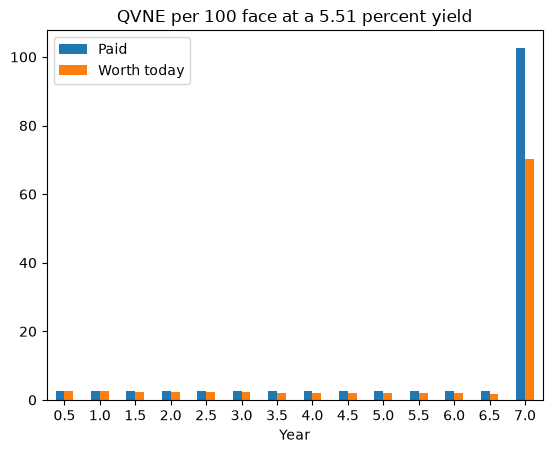

In [18]:
# pandas, imported as in Part 1; a row per payment, its year from the period number
import pandas as pd
flows = pd.DataFrame({'Year': periods / 2, 'Paid': cash_flows, 'Worth today': present_values})
chart = flows.plot.bar(x='Year', rot=0, title='QVNE per 100 face at a 5.51 percent yield')

Under these assumptions, a price of 98.50 and a yield of about 5.51 percent say the same thing.
102.625 due in year 7 is worth 70.15 today: most of the price.

**98.5067: within a cent of the desk's 98.50, with no loop.**

### A Yield Equal to the Coupon

The steps go in a function (week 1's Part 2), to price at any yield.

**Predict 3**

Q. What is QVNE's price at a yield of 5.25 percent, its own coupon?

A) Above 100.
B) Below 100.
C) Exactly 100.

In [19]:
def price_from_yield(coupon, years, yield_pct):
    """Price per 100 face: semiannual coupons, whole periods, settled on a coupon date."""
    periods = np.arange(1, years * 2 + 1)
    cash_flows = np.ones(periods.size) * coupon / 2
    cash_flows[-1] = cash_flows[-1] + 100
    discount_factors = 1 / (1 + yield_pct / 100 / 2) ** periods
    return (cash_flows * discount_factors).sum()


print('At 5.51:', round(price_from_yield(5.25, 7, 5.51), 4))
print('At 5.25:', round(price_from_yield(5.25, 7, 5.25), 4))

At 5.51: 98.5067
At 5.25: 100.0


C: each coupon pays exactly the yield on 100, so 100 is the price.

**Excel side by side.** `=SUMPRODUCT(B2:B15, C2:C15)` on the cash flows and discount factors, or `=PV(5.51%/2, 14, -2.625, -100)` in one step, gives 98.5067.

**Yield equal to coupon, price 100: test any pricing code on it.**

### Compounding All the Time

Q. A colleague discounts continuously: a payment `t` years away is worth e to the power of minus the yield times `t`. What price does 5.51 percent give?

In [20]:
# each payment's time in years
payment_years = periods / 2
# np.exp() raises e to a power, as in Part 1, for all 14 at once
continuous_factors = np.exp(-yield_pct / 100 * payment_years)
continuous_price = (cash_flows * continuous_factors).sum()
print('Twice a year:', round(qvne_price, 4))
print('Continuous:  ', round(continuous_price, 4))

Twice a year: 98.5067
Continuous:   98.0718


Compounding all the time earns more at the same quoted rate, so every payment is discounted harder.

**A yield means nothing without its convention. Now the whole book, every day.**

> STORY: In 1683 Jacob Bernoulli, working on compound interest, looked for the limit of (1 + 1/n) to the power n as n grows, and showed it lies between 2 and 3.
> That limit is e, about 2.718; the symbol e first appears in a letter Euler wrote to Goldbach in 1731.
>
> Source: [MacTutor History of Mathematics, "The number e"](https://mathshistory.st-andrews.ac.uk/HistTopics/e/)

## 6.7 The Book in One Table

### Four Bonds, Three Columns

Every array so far has been one column; a **2-D** array has rows and columns, like a block of cells.

Q. Put each bond's coupon, price, and face in one array, a row per bond.

In [21]:
# a list of lists becomes a 2-D array: each inner list is one row
bond_table = np.array([[5.25, 98.5, 1500000],
                       [6.125, 103.25, 500000],
                       [4.75, 95.0, 750000],
                       [7.5, 101.0, 250000]])
print(bond_table)

[[5.2500e+00 9.8500e+01 1.5000e+06]
 [6.1250e+00 1.0325e+02 5.0000e+05]
 [4.7500e+00 9.5000e+01 7.5000e+05]
 [7.5000e+00 1.0100e+02 2.5000e+05]]


Mixing 4.75 with 1,500,000, NumPy switched to scientific notation: `1.5e+06` is 1,500,000.

**Excel side by side.** The Scientific number format shows `1.50E+06`.

Q. Print plain numbers instead, then the table's dimensions and shape.

In [22]:
# suppress=True prints plain numbers from here on; the stored values do not change
np.set_printoptions(suppress=True)
print(bond_table)
# ndim and shape, as on Part 1's one-column arrays
print('ndim:', bond_table.ndim, 'shape:', bond_table.shape)

[[      5.25       98.5   1500000.   ]
 [      6.125     103.25   500000.   ]
 [      4.75       95.     750000.   ]
 [      7.5       101.     250000.   ]]
ndim: 2 shape: (4, 3)


### A Row, a Price, a Column, a Block

Q. Print DNMR's row, DNMR's price, the price column, and the first two bonds' coupon and price.

In [23]:
# one index picks a row: DNMR is row 1
print(bond_table[1])
# two indexes, row then column: DNMR's price
print(bond_table[1, 1])

[     6.125    103.25  500000.   ]
103.25


In [24]:
# a colon alone means every row: the price column
print(bond_table[:, 1])
# a slice in each place: rows 0 and 1, columns 0 and 1
print(bond_table[0:2, 0:2])

[ 98.5  103.25  95.   101.  ]
[[  5.25   98.5  ]
 [  6.125 103.25 ]]


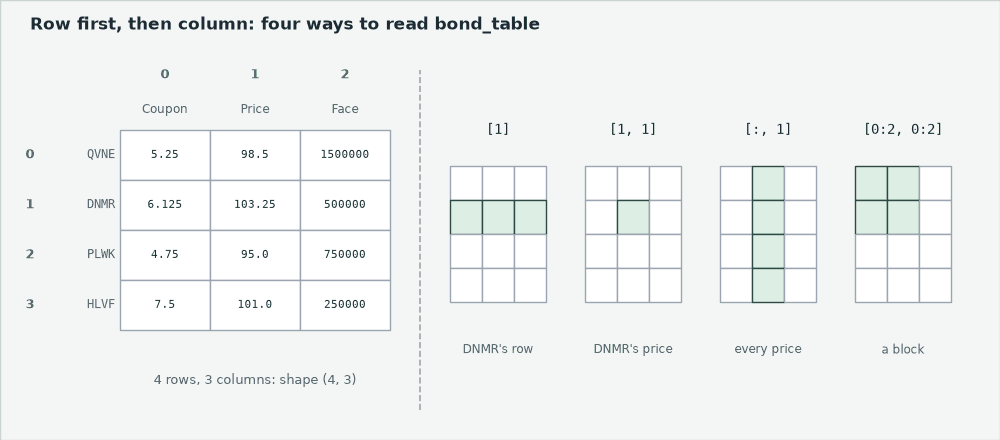

**Row first, then column; a colon alone takes them all.**

### Down Each Column

An **axis** is one direction of a table: `axis=0` runs down the rows, giving one result per column.

Q. What is the average of each column?

In [25]:
# axis=0: down the rows
print(bond_table.mean(axis=0))

[     5.90625     99.4375  750000.     ]


The coupon and price averages are 6.4's.
With no axis, `mean()` would average all twelve numbers, coupons with faces: meaningless.

### Across Each Row

`axis=1` suits columns of like numbers, as in `payments`: each bond's two coupon payments a year.

**Predict 4**

Q. `payments` has 4 rows and 2 columns. How many numbers does `payments.sum(axis=1)` give?

A) 2
B) 4
C) 1

In [26]:
# rows: the four bonds; columns: the first and second payment of each bond's year
payments = np.array([[39375.0, 39375.0], [15312.5, 15312.5],
                     [17812.5, 17812.5], [9375.0, 9375.0]])
print('axis=1:', payments.sum(axis=1))
print('axis=0:', payments.sum(axis=0))
print('no axis:', payments.sum())

axis=1: [78750. 30625. 35625. 18750.]
axis=0: [81875. 81875.]
no axis: 163750.0


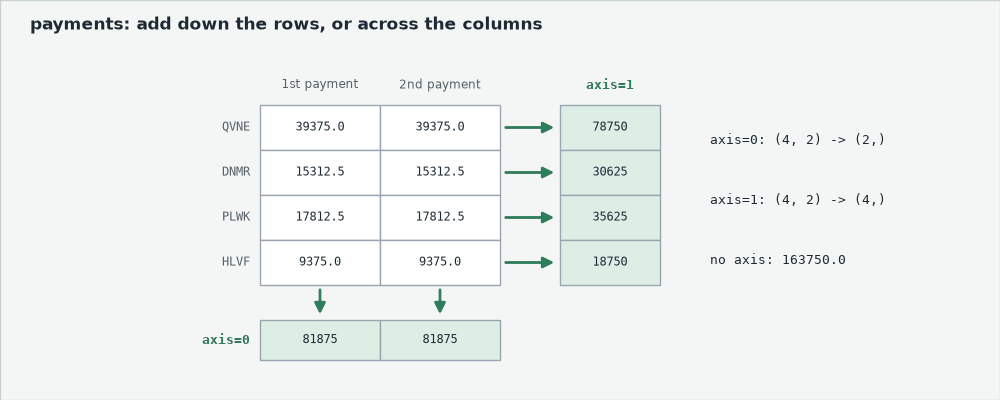

B: one total per bond, 6.3's four incomes.
`axis=0` totals the first payments, then the second: not a date, as each bond keeps its own coupon dates.

**Excel side by side.** `axis=0` is a `=SUM()` under each column; `axis=1`, a `=SUM()` at the end of each row.

**The axis you name is the one that disappears.**

### A Run of Twelve Closes

Q. The closes of QVNE, DNMR, and PLWK, Monday to Thursday, arrive as one run of twelve, bond by bond. Lay them out a row per bond, a column per day.

In [27]:
# QVNE's closes (Part 1's Monday to Thursday), then DNMR's, then PLWK's
flat_prices = np.array([98.5, 98.7, 98.4, 98.9,
                        103.25, 103.0, 102.8, 103.1,
                        95.0, 95.2, 95.4, 95.1])
# reshape((rows, columns)) lays the same numbers out, filling one row at a time
price_grid = flat_prices.reshape((3, 4))
print(price_grid)

[[ 98.5   98.7   98.4   98.9 ]
 [103.25 103.   102.8  103.1 ]
 [ 95.    95.2   95.4   95.1 ]]


**Excel side by side.** In Microsoft 365, with the twelve in A1:L1, `=WRAPROWS(A1:L1, 4)` spills the same grid.

### The Wrong Grid

Q. Lay the twelve out in 3 rows of 5.

In [28]:
# 12 closes into 3 rows of 5: this cell is meant to fail
flat_prices.reshape((3, 5))

ValueError: cannot reshape array of size 12 into shape (3,5)

Rows times columns must equal the count: 3 times 5 is 15, not 12.

### One Row per Day

Q. Turn the grid so each row is a day and each column a bond.

In [29]:
# .T is the transpose: rows become columns
print(price_grid.T)
print(price_grid.T.shape)

[[ 98.5  103.25  95.  ]
 [ 98.7  103.    95.2 ]
 [ 98.4  102.8   95.4 ]
 [ 98.9  103.1   95.1 ]]
(4, 3)


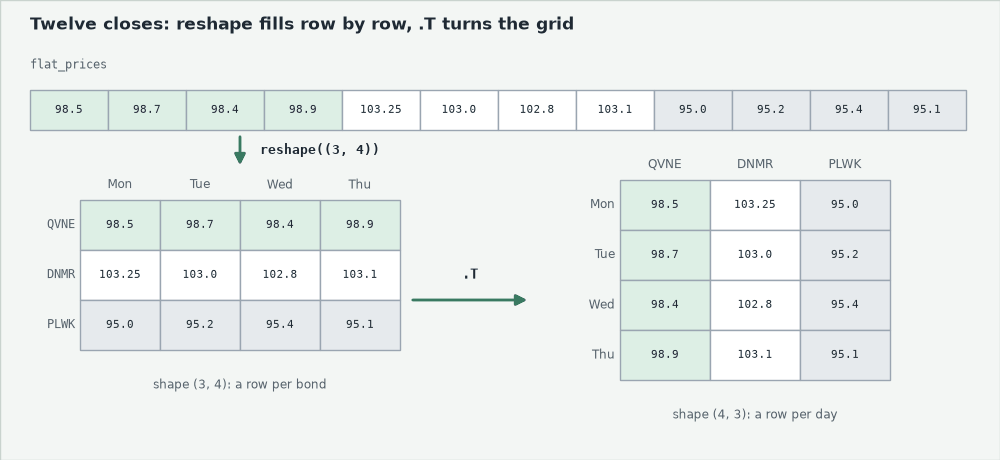

Q. Draw each bond's closes: one row per day is the shape a chart wants.

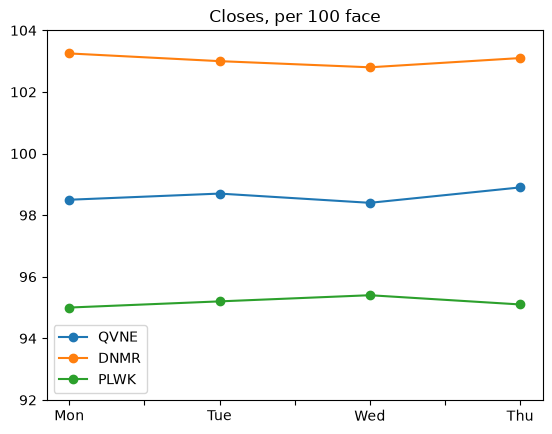

In [30]:
# columns= names the columns, index= the rows; each column becomes a line
days = pd.DataFrame(price_grid.T, columns=['QVNE', 'DNMR', 'PLWK'],
                    index=['Mon', 'Tue', 'Wed', 'Thu'])
# ylim= as in 6.4: room under the lines for the legend
chart = days.plot.line(marker='o', ylim=(92, 104), title='Closes, per 100 face')

### Overwrite Part of a Table

Q. In a copy of the grid, set DNMR's last two closes to 100.

In [31]:
# a table's slice is a window too, so work on a copy
grid_copy = price_grid.copy()
# row 1 is DNMR; 2: is its last two columns
grid_copy[1, 2:] = 100
print(grid_copy)

[[ 98.5   98.7   98.4   98.9 ]
 [103.25 103.   100.   100.  ]
 [ 95.    95.2   95.4   95.1 ]]


### Multiply and Add With @

**Predict 5**

Q. `@` is a new symbol. What does `cash_flows @ discount_factors` give?

A) 14 numbers, value by value, as `*` gives.
B) One number.
C) An error.

In [32]:
# 6.6's cash flows against 6.6's discount factors; np.round() as in Part 1
print(np.round(cash_flows @ discount_factors, 4))

98.5067


B: `@` multiplies value by value and adds up the products, Part 1's `SUMPRODUCT` in one symbol: here, QVNE's price.

Q. What was the three-bond book worth each day? The desk holds 1,500,000 QVNE, 500,000 DNMR, and 750,000 PLWK.

In [33]:
# the first three faces against each day's column of closes, over 100: one value per day
# (3,) @ (3, 4) gives (4,): the 3 faces meet the 3 rows, so those sizes must match
book_values = faces[:3] @ price_grid / 100
print(book_values)

[2706250. 2709500. 2705500. 2712250.]


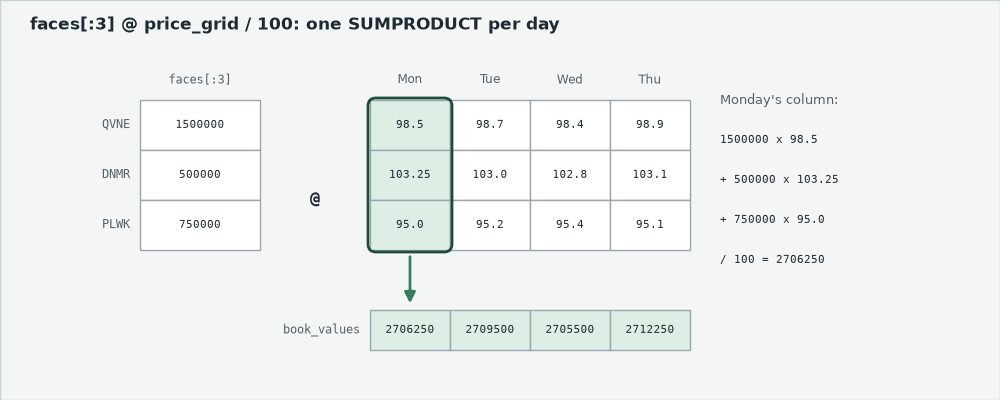

**Excel side by side.** Faces in B2:B4, the four days' closes in C2:F4:

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Monday's book</td><td align="left"><code>faces[:3] @ price_grid[:, 0] / 100</code></td><td align="left"><code>=SUMPRODUCT(B2:B4, C2:C4)/100</code></td></tr>
<tr><td align="left">Every day's book</td><td align="left"><code>faces[:3] @ price_grid / 100</code></td><td align="left"><code>=MMULT(TRANSPOSE(B2:B4), C2:F4)/100</code> (Microsoft 365)</td></tr>
<tr><td align="left">Turn the grid</td><td align="left"><code>price_grid.T</code></td><td align="left"><code>=TRANSPOSE(C2:F4)</code></td></tr>
</table>
<br clear="left">

### The Identity and a Grid of Zeros

Q. The **identity** has 1 on the diagonal and 0 elsewhere. What are the faces times the identity?

Q. Build a grid of zeros, 2 rows by 3 columns.

In [34]:
# np.eye(3): the 3 by 3 identity
identity = np.eye(3)
print(identity)
print(faces[:3] @ identity)
# np.zeros() also takes a shape, a tuple, rows first
print(np.zeros((2, 3)))

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[1500000.  500000.  750000.]
[[0. 0. 0.]
 [0. 0. 0.]]


The faces come back unchanged: the identity is the table version of multiplying by 1, a quick test of matrix code.
Excel's `=MUNIT(3)` spills it.

**One line values the book every day. Now keep it past today.**

## 6.8 Saving and Loading Arrays

### One Array, One File

Arrays live in memory and vanish when the notebook closes.
A file name with no folder lands in the working directory, as on Day 2.

Q. Save `prices` to a file, and load it back.

In [35]:
# np.save() writes one array in NumPy's own format, .npy
np.save('desk_prices.npy', prices)
# np.load() reads it back
loaded_prices = np.load('desk_prices.npy')
print(loaded_prices)

[ 98.5  103.25  95.   101.  ]


### A CSV Excel Can Open

Q. Save `bond_table` as a CSV file, then print what was written.

In [36]:
# delimiter=',': commas between columns; fmt='%.3f': 3 decimals, as :.3f in week 1's Part 1
# header=: a first line of names; comments='': no # in front of it
np.savetxt('desk_bond_table.csv', bond_table, delimiter=',', fmt='%.3f',
           header='coupon,price,face', comments='')
# read the file back as text, with Day 2's open()
with open('desk_bond_table.csv', 'r', encoding='utf-8') as file:
    print(file.read())

coupon,price,face
5.250,98.500,1500000.000
6.125,103.250,500000.000
4.750,95.000,750000.000
7.500,101.000,250000.000



An ordinary CSV, as Excel's Save As writes one, and no tickers: an array holds one type.

### Read It Back and Compare

Q. Load the CSV back and compare it with `bond_table`.

In [37]:
# np.loadtxt() reads a text file of numbers; skiprows=1 skips the header line
loaded_table = np.loadtxt('desk_bond_table.csv', delimiter=',', skiprows=1)
# np.array_equal(): True when the shapes and every value match
print(np.array_equal(loaded_table, bond_table))

True


With `fmt='%.2f'`, the 6.125 coupon would come back rounded and the check would say False.

### Several Arrays in One File, Then Clean Up

Q. Save `prices` and `faces` in one file, and read each back by name.

Q. Remove the three files and confirm each is gone.

In [38]:
# np.savez(): several arrays in one .npz file, each under the name left of its =
np.savez('desk_arrays.npz', prices=prices, faces=faces)
# with closes the file afterwards, as it did for open()
with np.load('desk_arrays.npz') as saved:
    # printed bare, saved shows only an object: pick each array by its name
    print(saved.files)
    print(saved['faces'])

['prices', 'faces']
[1500000  500000  750000  250000]


In [39]:
# Day 2's os: remove each file, then confirm it is gone
import os
for name in ['desk_prices.npy', 'desk_bond_table.csv', 'desk_arrays.npz']:
    os.remove(name)
    print(name, 'still there:', os.path.exists(name))

desk_prices.npy still there: False
desk_bond_table.csv still there: False
desk_arrays.npz still there: False


<table align="left">
<tr><th align="left">File</th><th align="left">Holds</th><th align="left">Every digit kept</th><th align="left">Excel opens it</th></tr>
<tr><td align="left"><code>.npy</code></td><td align="left">one array</td><td align="left">yes</td><td align="left">no</td></tr>
<tr><td align="left"><code>.npz</code></td><td align="left">several arrays, by name</td><td align="left">yes</td><td align="left">no</td></tr>
<tr><td align="left"><code>.csv</code></td><td align="left">one table of numbers, as text</td><td align="left">only the decimals written</td><td align="left">yes</td></tr>
</table>
<br clear="left">

**Saved and read back, numbers only. Names are pandas' job.**

## You Can Now

By the end of this notebook, you can:

* Pick bonds by position or by a mask, such as below par.
* Combine masks with `&` and `|`, and label bonds with `np.where()`.
* Change part of an array through a mask or a slice, on a `.copy()`.
* Price a bond from its cash flows, and test it at a yield equal to the coupon.
* Hold the book in a 2-D array and work along an axis, with `reshape`, `.T`, and `@`.
* Save arrays to files and check that they come back intact.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

A second desk holds three different bonds; the issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">A</td><td align="left">6</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">BBB-</td><td align="left">10</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">B</td><td align="left">15</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Replace each `...` with your own code, then run the check cell under it.
Run the next cell first: it stores the three bonds and defines `check`, which marks your answers.

In [40]:
import numpy as np


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    # isinstance(x, np.ndarray) is True when x is a NumPy array;
    # its .dtype.kind is 'f' when it holds decimals
    if isinstance(expected, np.ndarray) and expected.dtype.kind == 'f':
        # arrays of numbers: same shape, and every value within a small tolerance;
        # np.shape() gives the shape of a list too
        correct = np.shape(answer) == expected.shape and np.allclose(answer, expected)
    elif isinstance(expected, np.ndarray):
        # arrays of text: np.array_equal() is True for the same shape and the same values
        correct = np.array_equal(answer, expected)
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance;
        # abs() drops the sign, so this is the size of the gap between the two
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# the second desk's three bonds, one array per column
tickers = np.array(['TRNW', 'OSMC', 'CLDB'])
coupons = np.array([4.375, 5.0, 8.25])
prices = np.array([96.25, 100.0, 104.5])
faces = np.array([2000000, 1250000, 500000])
scores = np.array([6, 10, 15])

### Exercise 1

Q. Use a boolean mask to find the tickers of the bonds priced below par, and the total face held in investment grade bonds (a score of 10 or lower). Then use `np.where()` to label each bond 'Below par' when its price is under 100 and 'Par or above' otherwise. Store the answers in **ex1_below_par**, **ex1_ig_face**, and **ex1_labels**.

In [41]:
ex1_below_par = ...
ex1_ig_face = ...
ex1_labels = ...

In [42]:
check('Exercise 1 below par', ex1_below_par, np.array(['TRNW']))
check('Exercise 1 investment grade face', ex1_ig_face, 3250000)
check('Exercise 1 labels', ex1_labels,
      np.array(['Below par', 'Par or above', 'Par or above']))

Exercise 1 below par: not attempted yet
Exercise 1 investment grade face: not attempted yet
Exercise 1 labels: not attempted yet


### Exercise 2

The second desk's risk system wants the holdings as one table in a file, not as separate columns.

Q. Build a 2-D array with one row per bond and three columns: coupon, price, and face held. Store it in **ex2_table**. Find the average of each column and store it in **ex2_column_averages**. Then save the table to a file named `second_desk_table.csv` with `np.savetxt()`, using a comma as the delimiter and three decimal places, load it back with `np.loadtxt()`, and store the loaded array in **ex2_loaded**.

In [43]:
ex2_table = ...
ex2_column_averages = ...
ex2_loaded = ...

In [44]:
check('Exercise 2 table', ex2_table,
      np.array([[4.375, 96.25, 2000000.0], [5.0, 100.0, 1250000.0], [8.25, 104.5, 500000.0]]))
check('Exercise 2 column averages', ex2_column_averages, np.array([5.875, 100.25, 1250000.0]))
check('Exercise 2 loaded', ex2_loaded,
      np.array([[4.375, 96.25, 2000000.0], [5.0, 100.0, 1250000.0], [8.25, 104.5, 500000.0]]))

Exercise 2 table: not attempted yet
Exercise 2 column averages: not attempted yet
Exercise 2 loaded: not attempted yet


### Exercise 3

The second desk's closing prices for TRNW, OSMC, and CLDB on three days arrive as one run of 9 numbers, bond by bond: 96.25, 96.5, 96.0, then 100.0, 100.2, 100.1, then 104.5, 104.0, 104.25.

Q. Lay the prices out as a grid with one row per bond and one column per day, and store it in **ex3_grid**. Use `@` to find the market value of the whole book on each day, and store it in **ex3_book_values**. Then find the log return of the book from the first day to the last day, and store it in **ex3_log_return**.

In [45]:
ex3_grid = ...
ex3_book_values = ...
ex3_log_return = ...

In [46]:
check('Exercise 3 grid', ex3_grid, np.array([[96.25, 96.5, 96.0], [100.0, 100.2, 100.1],
                                            [104.5, 104.0, 104.25]]))
check('Exercise 3 book values', ex3_book_values, np.array([3697500.0, 3702500.0, 3692500.0]))
check('Exercise 3 log return', ex3_log_return, -0.00135318018)

Exercise 3 grid: not attempted yet
Exercise 3 book values: not attempted yet
Exercise 3 log return: not attempted yet


### Exercise 4

OSMC has a 5 percent coupon.

Give it exactly 5 years to maturity and price it per 100 of face at a yield of 6 percent, with the three assumptions of section 6.6: whole periods, semiannual compounding, and settlement on a coupon date.

Q. Build the cash flows in **ex4_cash_flows**, the discount factors in **ex4_discount_factors**, and the price in **ex4_price**.

In [47]:
ex4_cash_flows = ...
ex4_discount_factors = ...
ex4_price = ...

In [48]:
check('Exercise 4 last cash flow',
      None if ex4_cash_flows is ... else ex4_cash_flows[-1], 102.5)
check('Exercise 4 first discount factor',
      None if ex4_discount_factors is ... else ex4_discount_factors[0], 1 / 1.03)
check('Exercise 4 price', ex4_price, 95.73489858)

Exercise 4 last cash flow: not attempted yet
Exercise 4 first discount factor: not attempted yet
Exercise 4 price: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that prices a bond from its yield, with the assumptions of section 6.6; it has one bug.

Q. Read the code before you run it. What number do you expect? You worked out the price of OSMC at a yield of 6 percent yourself in Exercise 4. Then run the code. Does it agree with you?

Q. Find the bug and fix the code below, so that **ex5_price** holds the right answer.

In [49]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def ai_price(coupon, years, yield_pct):
    """
    Take an annual coupon in percent, a whole number of years to maturity,
    and an annual yield in percent,
    and return the price per 100 of face.
    Assumes semiannual coupons and settlement on a coupon date.
    """
    periods = np.arange(1, years * 2 + 1)
    cash_flows = np.ones(periods.size) * coupon / 2
    cash_flows[-1] = cash_flows[-1] + 100
    discount_factors = 1 / (1 + yield_pct / 100) ** periods
    return (cash_flows * discount_factors).sum()


ex5_price = ai_price(5.0, 5, 6.0)
print(f'The price of OSMC at a yield of 6 percent is {round(ex5_price, 4)}')

The price of OSMC at a yield of 6 percent is 74.2397


In [50]:
check('Exercise 5', ex5_price, 95.73489858)

Exercise 5: not yet. You have 74.23969532004853


In [51]:
# run this cell last: it removes the file Exercise 2 created
import os

# remove the file from Exercise 2, if it was created
if os.path.exists('second_desk_table.csv'):
    os.remove('second_desk_table.csv')

print('second_desk_table.csv still there:', os.path.exists('second_desk_table.csv'))

second_desk_table.csv still there: False


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Below par</td><td align="left">QVNE and PLWK, 2,250,000 of face, from one mask</td></tr>
<tr><td align="left">High yield</td><td align="left">DNMR and HLVF, 49,375 a year</td></tr>
<tr><td align="left">The cheap ones up a point</td><td align="left">99.5 and 96, on a copy</td></tr>
<tr><td align="left">QVNE's 98.50</td><td align="left">98.5067, from its cash flows</td></tr>
<tr><td align="left">The book each day</td><td align="left">2,706,250 to 2,712,250, from one <code>@</code></td></tr>
<tr><td align="left">Saved for tomorrow</td><td align="left">three files, read back equal</td></tr>
</table>
<br clear="left">

Be proud: you priced a bond from its cash flows and landed within a cent of the desk's own number.

The CSV came back without its tickers: an array holds one type and no names.
Day 2's pandas puts names on the rows and columns, and the book grows to two hundred bonds.